<a href="https://colab.research.google.com/github/Banking-Analytics-Lab/DLinBankingBook/blob/main/Labs/TextBook_Lab_Chap2_LiDAR_Deprivation_London.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LiDAR Elevation and Neighborhood Deprivation in London

*Deep Learning in Banking* (Bravo, Maldonado and Óskarsdóttir, Wiley, 2026), Chapter 2: updated case study (2026).

> **New case (2026).** This case replaces the case study printed in Chapter 2 of the book. The original case, which predicts the loan delinquency ratio of US areas from LiDAR images, is still available and corrected: [open it in Colab](https://colab.research.google.com/github/Banking-Analytics-Lab/DLinBankingBook/blob/main/Labs/TextBook_Lab_Chap2_Image_Processing.ipynb) or [view it on GitHub](https://github.com/Banking-Analytics-Lab/DLinBankingBook/blob/main/Labs/TextBook_Lab_Chap2_Image_Processing.ipynb).

Banks already describe a borrower's neighborhood with tables: average income, unemployment, house prices. This lab asks whether an **image of the neighborhood** adds anything to those tables. We use LiDAR, a laser survey from an aircraft that measures the height of everything on the ground: buildings, trees, roads. From LiDAR we compute the height above ground of every square meter of Greater London, cut it into tiles of 200 m by 200 m, and use a pretrained convolutional neural network (CNN) to turn each tile into a vector of numbers.

The target is the **English Indices of Deprivation 2019**, the official measure of how deprived each small area of England is. It has seven domains: income, employment, education, health, crime, barriers to housing and services, and living environment.

The lab has two parts.

**Part 1 (Sections 1 to 9) follows the book.** For one domain, living environment, we train the two networks of Chapter 2 on the LiDAR tiles alone: a simple CNN trained from scratch, and a pretrained network that we fine-tune. Each section names the algorithm of the book that it implements (Algorithms 2.1 to 2.9). The book fine-tunes a ResNet-50; we fine-tune EfficientNet-B0, which is smaller and faster, and the [original Chapter 2 lab](https://colab.research.google.com/github/Banking-Analytics-Lab/DLinBankingBook/blob/main/Labs/TextBook_Lab_Chap2_Image_Processing.ipynb) has the ResNet-50 version. The simple CNN does only modestly better than a naive baseline, whereas the fine-tuned network is a pretty good model: for living environment, it does better than the six other domains.

**Part 2 (Sections 10 to 16) goes beyond the book.** A bank never uses an image alone: it already has structured data. Part 2 asks whether the image adds to that data, for all seven domains. For each domain, we compare three models:

- **D:** the other six domains only. This plays the role of the structured data a bank already has.
- **I:** the LiDAR image features only.
- **D+I:** both.

The question is whether **D+I beats D**. The answer is yes for every domain, by about 3 to 17 percent, while I alone is much worse than D for every domain but one. That is the typical pattern for images in banking: an image rarely replaces structured data, but it can add to it.

The lab re-implements, with open data and a simpler network, the study of [Stevenson, Mues and Bravo (2022)](https://arxiv.org/html/2112.01421v2).

**Before you start:** select a GPU runtime (*Runtime → Change runtime type → T4 GPU*). The notebook runs in about 30 minutes on a free Colab T4.

**Data and licenses.** All data are open and used under the Open Government Licence v3.0:
- LiDAR Composite DTM and DSM (first return), 1 m, 2022: © Environment Agency copyright and/or database right.
- LSOA 2011 boundaries: Source: Office for National Statistics, licensed under the Open Government Licence v.3.0. Contains OS data © Crown copyright and database right.
- English Indices of Deprivation 2019: Ministry of Housing, Communities and Local Government.

Do not upload bank or customer data to Colab.

## 0. Setup

Almost everything we need comes with Colab: PyTorch and torchvision for the networks, LightGBM and scikit-learn for the models of Part 2, and OpenCV, pandas and Matplotlib for the rest. We install two small packages: `livelossplot` to plot the losses during training, and `torchcam` for Grad-CAM. We install both with `--no-deps`, so that pip does not touch the packages Colab depends on.

We then import the packages, fix the random seeds so that you get the same results every time, and check that PyTorch sees the GPU, as Algorithm 2.1 asks.

In [1]:
!pip install -q --no-deps livelossplot torchcam

In [2]:
import os
import time
import random
import zipfile
import warnings
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from livelossplot import PlotLosses

import torch
import torch.nn as nn
import torchvision
from torchcam.methods import SmoothGradCAMpp
from torch.utils.data import Dataset, DataLoader

import lightgbm as lgb
from sklearn.decomposition import PCA
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")   # LightGBM and LassoCV are chatty; the results are unaffected.


def set_seed(seed):
    # Fix every random number generator used in the lab.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "(no GPU: the lab still runs, but slowly)")

Device: cuda NVIDIA GeForce RTX 5090


## 1. The data (Algorithm 2.1)

The archive `london_lidar_iod2019.zip` (about 680 MB) has three things:

- `tiles/`: 39,367 grayscale images of 200 × 200 pixels. Each pixel is one square meter, and its value is the **height above ground**, from 0 m (black) to 30 m (white), so one grey level is about 0.12 m. A tall office block is white, a two-story house is dark purple, a park is black with speckles where the trees are.
- `tiles.csv`: one row per tile, with its position (the lower-left corner in British National Grid meters, `E` and `N`) and the small area it belongs to (`LSOA11CD`).
- `labels.csv`: one row per small area, with its borough and the seven deprivation scores.

The small areas are **Lower Layer Super Output Areas** (LSOAs), the units of the English census: about 1,500 residents each, and 4,835 of them in Greater London. They are grouped into 33 **boroughs** (Local Authority Districts).

**How the tiles were built.** For each 2 km block of London, we downloaded two rasters from the Environment Agency: the digital terrain model (DTM, the bare ground) and the digital surface model (DSM, the top of whatever stands on the ground, first laser return). Their difference, DSM minus DTM, is the height of objects above ground, called the normalized DSM (nDSM). We cut it into 200 m tiles and assigned each tile to the LSOA that contains its center (19 very small LSOAs contain no tile center and get the tile under their own center). The script that does this, `build_london_tiles.py`, is on the book website; it takes about 20 minutes and needs no GPU, so we start from its output.

In [3]:
# Download the archive (about 680 MB) from the book's shared folder. gdown fetches public
# Google Drive files; the link is read-only. If the cell is run twice, it skips the download.
if not os.path.exists("london_lidar_iod2019"):
    # The bare file id works with every gdown version (--fuzzy was removed in gdown 6).
    !gdown -q 1MUJkpWlS2c7r_InQN60rxIuPLjCjpcGj
    # Extracting 39,367 small images takes about a minute.
    with zipfile.ZipFile("london_lidar_iod2019.zip") as z:
        z.extractall(".")

DATA = "london_lidar_iod2019"
tiles = pd.read_csv(f"{DATA}/tiles.csv")
labels = pd.read_csv(f"{DATA}/labels.csv")
print(f"{len(tiles):,} tiles in {tiles.LSOA11CD.nunique():,} LSOAs; {len(labels):,} LSOAs in {labels.LAD19CD.nunique()} boroughs")

39,367 tiles in 4,835 LSOAs; 4,835 LSOAs in 33 boroughs


### 1.1 The targets

Each domain score measures a different side of deprivation. The **income** and **employment** scores are the share of residents receiving income-related or employment-related benefits. The other scores combine several indicators: for example, **living environment** combines housing in poor condition, houses without central heating, air quality and road traffic accidents, and **barriers** combines overcrowding, housing affordability and the road distance to shops, schools and doctors.

The scores are on different scales, so, as in Stevenson et al. (2022), we rescale each one to the range 0 to 100 (0 is the least deprived area of London, 100 the most deprived). All errors in this lab are on that scale.

In [4]:
DOMAINS = ["income", "employment", "education", "health", "crime", "barriers", "living_env"]

labels = labels.set_index("LSOA11CD")
for d in DOMAINS:
    # Min-max scaling to 0-100. This uses the whole dataset, but it is a fixed, monotone
    # rescaling of the target: it changes no ranking and leaks nothing about the features.
    labels[d] = 100 * (labels[d] - labels[d].min()) / (labels[d].max() - labels[d].min())

# How do the domains relate to each other? High correlations mean the other six domains
# will already predict a domain well, which makes the structured baseline (D) strong.
corr = labels[DOMAINS].corr().round(2)
corr

,income,employment,education,health,crime,barriers,living_env
income,1.00,0.95,0.71,0.78,0.50,0.56,0.10
employment,0.95,1.00,0.69,0.77,0.47,0.48,0.05
education,0.71,0.69,1.00,0.56,0.33,0.46,-0.11
health,0.78,0.77,0.56,1.00,0.49,0.45,0.18
crime,0.50,0.47,0.33,0.49,1.00,0.31,0.36
barriers,0.56,0.48,0.46,0.45,0.31,1.00,0.11
living_env,0.10,0.05,-0.11,0.18,0.36,0.11,1.00


Most domains are strongly correlated. Income and employment are almost the same measure (correlation 0.95), so the six other domains predict income very well even without any image. Living environment is almost unrelated to the rest (no correlation above 0.36), and crime and barriers are only moderately related: those are the domains where the structured baseline is weakest and where an image has the most room to help.

### 1.2 Looking at the tiles

Before any model, look at the images. The function below builds a 400 m × 400 m picture of an area from a block of four adjacent tiles. We show the three London areas with the **least** deprived living environment and the three with the **most** deprived.

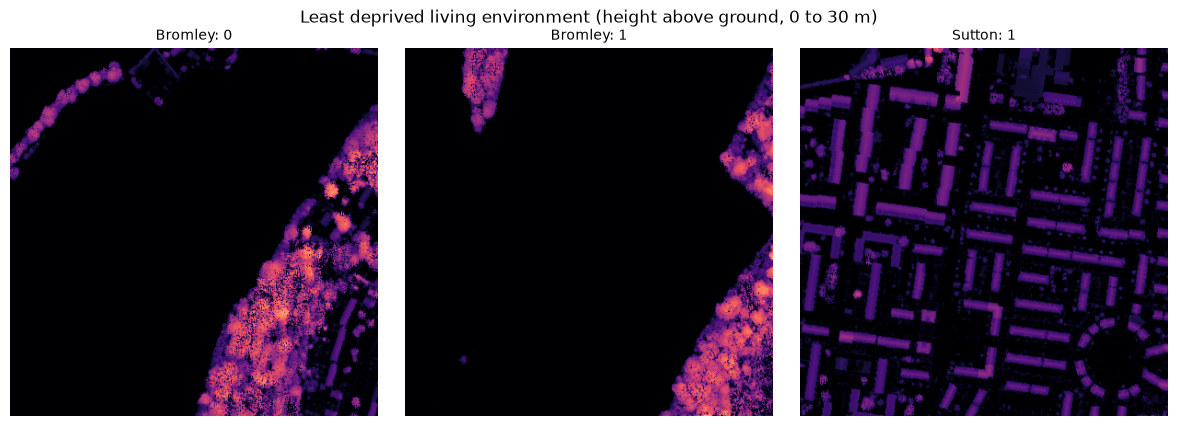

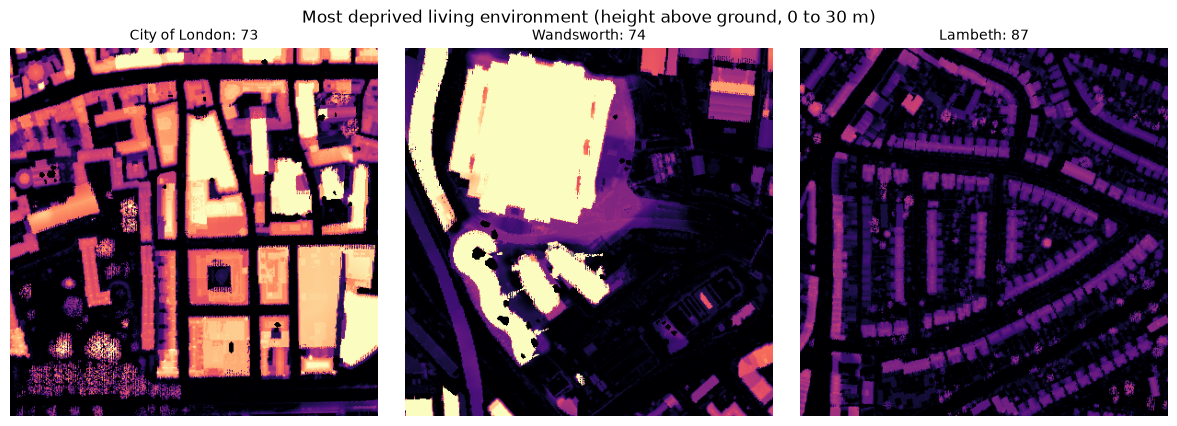

In [5]:
def block(code):
    """Lower-left corner of a 2 x 2 block of adjacent tiles inside the LSOA, or None."""
    t = tiles[tiles.LSOA11CD == code]
    have = set(zip(t.E, t.N))
    for e, n in sorted(have):
        if {(e + 200, n), (e, n + 200), (e + 200, n + 200)} <= have:
            return e, n
    return None


def mosaic(code):
    """400 m x 400 m image of an LSOA from four adjacent tiles, north at the top."""
    e, n = block(code)
    tid = tiles[tiles.LSOA11CD == code].set_index(["E", "N"]).tile_id
    tile = lambda x, y: np.asarray(Image.open(f"{DATA}/tiles/{tid[(x, y)]}.png"))
    return np.vstack([np.hstack([tile(e, n + 200), tile(e + 200, n + 200)]),
                      np.hstack([tile(e, n), tile(e + 200, n)])])


def show_areas(codes, titles, suptitle):
    fig, ax = plt.subplots(1, len(codes), figsize=(4 * len(codes), 4.3))
    for a, c, t in zip(np.atleast_1d(ax), codes, titles):
        a.imshow(mosaic(c), cmap="magma", vmin=0, vmax=255)
        a.set_title(t, fontsize=10)
        a.axis("off")
    fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()


# Areas with a 2 x 2 block, sorted from least to most deprived living environment.
ordered = [c for c in labels.sort_values("living_env").index if block(c) is not None]
for group, name in [(ordered[:3], "Least deprived living environment"), (ordered[-3:], "Most deprived living environment")]:
    show_areas(group, [f"{labels.LAD19NM[c]}: {labels.living_env[c]:.0f}" for c in group],
               name + " (height above ground, 0 to 30 m)")

The least deprived areas are low and green: open land fringed by woodland on the edge of London, or regular streets of houses with gardens. The most deprived areas look very different: dense, tall blocks in central London (white is 30 m or more), large buildings, or tight terraces with little green space. Can a network learn to read the living environment from these heights? Part 1 trains two networks to find out.

### 1.3 Training, validation and test areas (Algorithm 2.1, data splitting)

Algorithm 2.1 splits the data into training, validation and test sets. Here we cannot split the areas at random. Neighboring areas look alike and have similar deprivation, so a random split would put the next-door neighbors of training areas in the test set, and every model would look better than it is on a part of London it has never seen. This is the spatial version of the leakage problem in the Chapter 3 lab, where every model may only use the months before the target window.

We therefore split by **borough**: every area of a borough is on the same side of the split. The function below assigns the 33 boroughs to five groups at random. Part 2 uses each group as a test set in turn. Part 1 trains each network once, so it takes the first group as its test set, a fifth of the remaining boroughs for validation, and the rest for training.

In [6]:
def borough_folds(groups, k=5, repeats=3, seed=0):
    """Group k-fold over boroughs, repeated with a new random assignment each time.

    Yields (repeat, fold, train_index, test_index). Every area of a borough is always on the
    same side of the split.
    """
    boroughs = np.unique(groups)
    rng = np.random.default_rng(seed)
    for r in range(repeats):
        perm = rng.permutation(boroughs)
        for f in range(k):
            test = np.isin(groups, perm[f::k])
            yield r, f, np.where(~test)[0], np.where(test)[0]


groups = labels.LAD19NM.values
_, _, rest, test_areas = next(borough_folds(groups))              # the first group of boroughs is the test set
rest_boroughs = np.unique(groups[rest])
val_boroughs = np.random.default_rng(1).choice(rest_boroughs, size=len(rest_boroughs) // 5, replace=False)

labels["split"] = np.where(np.isin(groups, val_boroughs), "val", "train")
labels.iloc[test_areas, labels.columns.get_loc("split")] = "test"
for s in ["train", "val", "test"]:
    b = sorted(set(groups[labels.split == s]))
    print(f"{s:>5}: {(labels.split == s).sum():,} areas in {len(b)} boroughs" + (f" ({', '.join(b)})" if s != "train" else ""))

train: 3,092 areas in 21 boroughs
  val: 721 areas in 5 boroughs (Barking and Dagenham, Hillingdon, Hounslow, Newham, Waltham Forest)
 test: 1,022 areas in 7 boroughs (Barnet, Bexley, Bromley, City of London, Ealing, Haringey, Sutton)


## 2. Data loaders (Algorithm 2.2)

The book has one image per area. Here an area has from 1 to almost 400 tiles (the median is 5), and the labels belong to the areas. We therefore train on the **tiles**, give every tile the score of its area, and predict an area by the **average** of the predictions for its tiles. This has two consequences:

- The labels are noisy. A park tile in a deprived area gets the area's score.
- Large areas have many tiles and would dominate the training. We give each tile a weight of one over the number of tiles in its area, so that every area counts once.

The target is the living-environment score divided by 100, so that it lies between 0 and 1, like the delinquency ratio in the book.

We read all 39,367 tiles into memory once (about 1.6 GB as bytes). The tiles already have a fixed size, 200 × 200 pixels, so we do not resize them. The dataset serves the raw bytes, the target and the weight. The transformation of Algorithm 2.2, from pixel values to the range −1 to 1 (mean 0.5 and standard deviation 0.5), runs on the GPU on whole batches, which is much faster than on Colab's two CPU cores. During training we also flip the tiles and turn them by quarter turns at random: seen from above, a neighborhood has no preferred orientation, and the network gets more varied examples.

In [7]:
# Read every tile once (a minute or two on Colab); threads overlap the reading and decoding.
t0 = time.time()
with ThreadPoolExecutor(8) as pool:
    images = np.stack(list(pool.map(lambda t: np.asarray(Image.open(f"{DATA}/tiles/{t}.png").convert("L")), tiles.tile_id)))
print(f"{images.shape[0]:,} tiles of {images.shape[1]} x {images.shape[2]} pixels read in {time.time() - t0:.0f} s")

TARGET = "living_env"
area_of_tile = labels.index.get_indexer(tiles.LSOA11CD)          # row of each tile's area in the label table
tiles_per_area = np.bincount(area_of_tile, minlength=len(labels))
y_area = labels[TARGET].values / 100                              # 0 to 1, like the book's ratio
tile_split = labels.split.values[area_of_tile]


class TileDataset(Dataset):
    """Serves (tile as bytes, area score, tile weight) for the tiles of one split."""
    def __init__(self, split):
        self.idx = np.where(tile_split == split)[0]
        self.targets = torch.tensor(y_area[area_of_tile[self.idx]], dtype=torch.float32)
        self.weights = torch.tensor(1 / tiles_per_area[area_of_tile[self.idx]], dtype=torch.float32)

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        return torch.from_numpy(images[self.idx[i]]), self.targets[i], self.weights[i]


def prepare(x, augment=False):
    """Bytes on the GPU -> values from -1 to 1, with random flips and quarter turns when training."""
    x = x.to(device).unsqueeze(1).float().div(255).sub(0.5).div(0.5)     # (batch, 1, 200, 200)
    if augment:
        if random.random() < 0.5:
            x = x.flip(-1)
        x = torch.rot90(x, random.randint(0, 3), dims=(-2, -1))
    return x


BATCH_SIZE = 128
datasets = {s: TileDataset(s) for s in ["train", "val", "test"]}
loaders = {s: DataLoader(datasets[s], batch_size=BATCH_SIZE, shuffle=(s == "train")) for s in datasets}
for s in datasets:
    print(f"{s:>5}: {len(datasets[s]):,} tiles, {len(loaders[s])} batches")

39,367 tiles of 200 x 200 pixels read in 16 s
train: 21,547 tiles, 169 batches
  val: 7,089 tiles, 56 batches
 test: 10,731 tiles, 84 batches


Four training tiles, with the living-environment score of their area as the title:

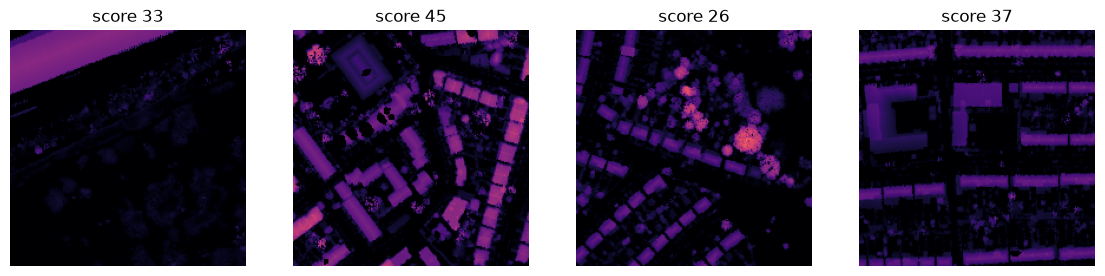

In [8]:
x, y, w = next(iter(loaders["train"]))
fig, ax = plt.subplots(1, 4, figsize=(14, 3.8))
for a, img, target in zip(ax, x[:4], y[:4]):
    a.imshow(img, cmap="magma", vmin=0, vmax=255)
    a.set_title(f"score {100 * target:.0f}")
    a.axis("off")
plt.show()

## 3. A simple CNN (Algorithm 2.3)

This is the network of the book, unchanged except for the input size. It has two parts:

1. **Feature extractor:** two blocks of convolution → batch normalization → ReLU → max pooling. Each 3 × 3 convolution with padding 1 keeps the spatial size, and each 2 × 2 pooling halves it.
2. **Regression head:** flatten the feature maps, then a dense layer with 256 units, dropout of 0.5, and one linear output unit.

| Layer | Output shape |
|---|---|
| Input | 1 × 200 × 200 |
| Block 1: 64 filters, then pooling | 64 × 100 × 100 |
| Block 2: 32 filters, then pooling | 32 × 50 × 50 |
| Flatten | 80,000 |
| Dense | 256 |
| Output | 1 |

Almost all the parameters sit in the first dense layer. We start the bias of the output unit at the mean training score, so the network starts from the naive prediction and spends its training on the differences between areas.

In [9]:
class SimpleCNN(nn.Module):
    def __init__(self, input_channels=1):   # 1 for grayscale, 3 for RGB
        super().__init__()

        # Feature extractor: two convolutional blocks.
        self.conv_layers = nn.Sequential(
            nn.Conv2d(input_channels, 64, kernel_size=3, stride=1, padding=1),  # index 0
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),                              # 200 -> 100

            nn.Conv2d(64, 32, kernel_size=3, stride=1, padding=1),              # index 4: last convolution
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),                              # 100 -> 50
        )

        # Regression head: flatten, one hidden dense layer, one output.
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 50 * 50, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        return self.fc_layers(self.conv_layers(x))


def count_parameters(model):
    # Total and trainable parameters.
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


train_mean = y_area[labels.split == "train"].mean()
set_seed(0)
simple_cnn = SimpleCNN(input_channels=1).to(device)
with torch.no_grad():
    simple_cnn.fc_layers[-1].bias.fill_(train_mean)               # start from the naive prediction

total, trainable = count_parameters(simple_cnn)
first_dense = sum(p.numel() for p in simple_cnn.fc_layers[1].parameters())
print(f"Parameters: {total:,} ({trainable:,} trainable)")
print(f"First dense layer: {first_dense:,} ({first_dense / total:.1%} of the total)")

Parameters: 20,499,809 (20,499,809 trainable)
First dense layer: 20,480,256 (99.9% of the total)


## 4. Training (Algorithm 2.4)

The training loop is the one of the book, written once as a function for both networks of Part 1. At every epoch it puts the model in training mode, runs every training batch (forward pass, loss, backward pass, optimizer step), then puts the model in evaluation mode, computes the validation error without gradients, **saves the model whenever the validation error improves**, and updates the live plot of the losses. Three details differ from the book:

1. The loss is the **weighted** mean squared error, with the tile weights of Section 2.
2. The validation error is computed for **areas**, not tiles: we average the predictions of each area's tiles and compare them with the area's score. That is the error we report in the end, so it is the one we use to choose the best epoch. We report it as an RMSE on the 0 to 100 scale.
3. We train in **mixed precision**, which the book uses in the case study of Section 7.5. On a T4 it roughly halves the training time.

The option `freeze_bn` is used for EfficientNet-B0 in Section 8. You can ignore it for now.

In [10]:
@torch.no_grad()
def predict_areas(model, split):
    """Average the clamped tile predictions of each area of a split; returns (area rows, predictions)."""
    model.eval()
    out = []
    for x, _, _ in loaders[split]:
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            out.append(model(prepare(x)).float().squeeze(1).clamp(0, 1).cpu())
    tile_pred = torch.cat(out).numpy()
    rows = area_of_tile[datasets[split].idx]
    area_pred = np.bincount(rows, weights=tile_pred, minlength=len(labels)) / np.maximum(np.bincount(rows, minlength=len(labels)), 1)
    areas = np.unique(rows)
    return areas, area_pred[areas]


def area_rmse(model, split):
    areas, pred = predict_areas(model, split)
    return 100 * np.sqrt(np.mean((pred - y_area[areas]) ** 2))      # on the 0-100 scale


def keep_frozen_batchnorm_in_eval(model):
    # A frozen batch-norm layer should not update its running statistics either.
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d) and not any(p.requires_grad for p in module.parameters()):
            module.eval()


def train_model(model, optimizer, epochs, checkpoint_path, freeze_bn=False):
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == "cuda")
    liveloss = PlotLosses()
    best_val_rmse = float("inf")

    for epoch in range(epochs):
        # Training phase
        model.train()
        if freeze_bn:
            keep_frozen_batchnorm_in_eval(model)
        running_loss, running_weight = 0.0, 0.0
        for x, y, w in loaders["train"]:
            x, y, w = prepare(x, augment=True), y.to(device), w.to(device)
            optimizer.zero_grad()                                    # Clear the gradients of the last step
            with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
                outputs = model(x).squeeze(1)
            loss = (w * (outputs.float() - y) ** 2).sum() / w.sum()  # weighted MSE: every area counts once
            scaler.scale(loss).backward()                            # Backpropagation (scaled for float16)
            scaler.step(optimizer)                                   # Update the weights
            scaler.update()
            running_loss += loss.item() * w.sum().item()
            running_weight += w.sum().item()
        train_rmse = 100 * np.sqrt(running_loss / running_weight)

        # Validation phase: no dropout, no gradients, error for areas
        val_rmse = area_rmse(model, "val")

        # Keep the best model seen so far
        if val_rmse < best_val_rmse:
            best_val_rmse = val_rmse
            torch.save(model.state_dict(), checkpoint_path)

        liveloss.update({"rmse": train_rmse, "val_rmse": val_rmse})
        liveloss.send()

    print(f"Training complete. Best validation RMSE: {best_val_rmse:.2f}, saved to {checkpoint_path}")

We train the simple CNN for 20 epochs with the Adam optimizer and a learning rate of $10^{-5}$, the rate the book found best for its simple CNN (Figure 2.6). Larger rates fail here. In our runs, at $10^{-4}$ and $10^{-3}$ the network soon predicted almost the same score for every area and stopped learning. A likely reason is the first dense layer: it has 80,000 inputs, and Adam moves every weight by about the learning rate at each step, so a large rate pushes the hidden units into the flat, negative side of the ReLU, where they stop learning. Exercise 1 asks you to try it.

The training error is computed on tiles and the validation error on areas, so the two curves are not on the same footing: the validation error is lower because averaging the tiles of an area cancels part of the noise.

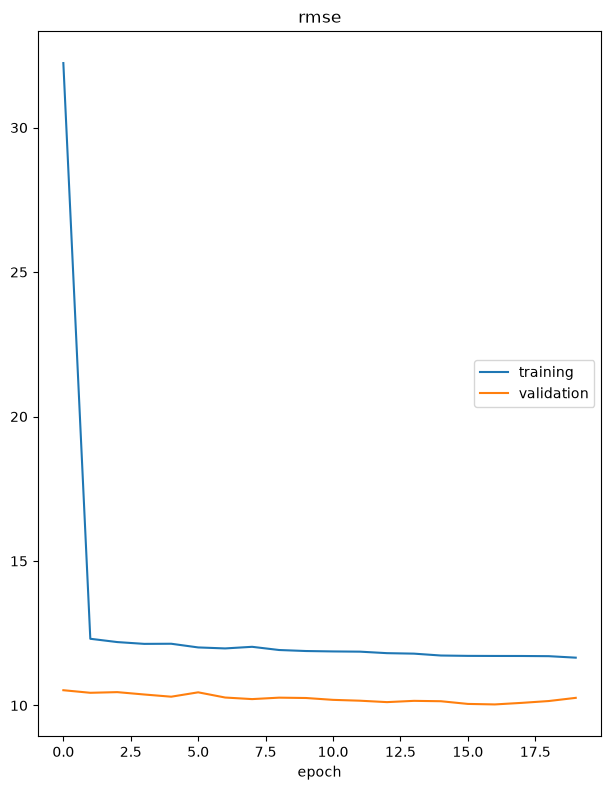

rmse
	training         	 (min:   11.654, max:   32.234, cur:   11.654)
	validation       	 (min:   10.035, max:   10.527, cur:   10.262)
Training complete. Best validation RMSE: 10.03, saved to best_simple_cnn.pth
1.9 minutes


In [11]:
set_seed(0)
optimizer = torch.optim.Adam(simple_cnn.parameters(), lr=1e-5)
t0 = time.time()
train_model(simple_cnn, optimizer, epochs=20, checkpoint_path="best_simple_cnn.pth")
print(f"{(time.time() - t0) / 60:.1f} minutes")

## 5. Evaluation on the test set (Algorithm 2.5)

We load the best checkpoint, put the model in evaluation mode, predict the tiles of the test boroughs, clamp the predictions to the valid range (0 to 1), average them by area, and compute the RMSE. As in the original lab, we compare it with a **naive baseline**: predicting the mean score of the training areas for every area. A model that cannot beat this baseline has learned nothing useful.

In [12]:
results = []


def report(name, areas, pred):
    rmse = 100 * np.sqrt(np.mean((pred - y_area[areas]) ** 2))
    print(f"{name:<34} test RMSE = {rmse:5.2f}")
    results.append({"model": name, "test RMSE": rmse})


test_rows = np.where(labels.split == "test")[0]
report("Naive baseline: training mean", test_rows, np.full(len(test_rows), train_mean))

simple_cnn.load_state_dict(torch.load("best_simple_cnn.pth", map_location=device, weights_only=True))
report("Simple CNN", *predict_areas(simple_cnn, "test"))

Naive baseline: training mean      test RMSE = 12.73


Simple CNN                         test RMSE = 10.89


**Compare the CNN with the baseline.** The simple CNN beats the naive baseline, with a test RMSE of about 10.9 against 12.7. It has learned something from the heights alone, but not much, and its validation error barely moves after the first few epochs. In the original Chapter 2 case, the simple CNN could not beat its baseline at all. A network trained from scratch on about 3,000 areas has little to work with. Section 7 asks whether a pretrained network does better.

## 6. What does the model look at? Grad-CAM (Algorithm 2.6)

As in the book, we use Smooth Grad-CAM++ (Omeiza et al., 2019) on the last convolutional layer of the simple CNN. It shows which parts of a tile push the prediction. We look at three test tiles: from the test area with the least deprived living environment, from one in the middle, and from the most deprived. In each area we take the tile with the most built-up surface.

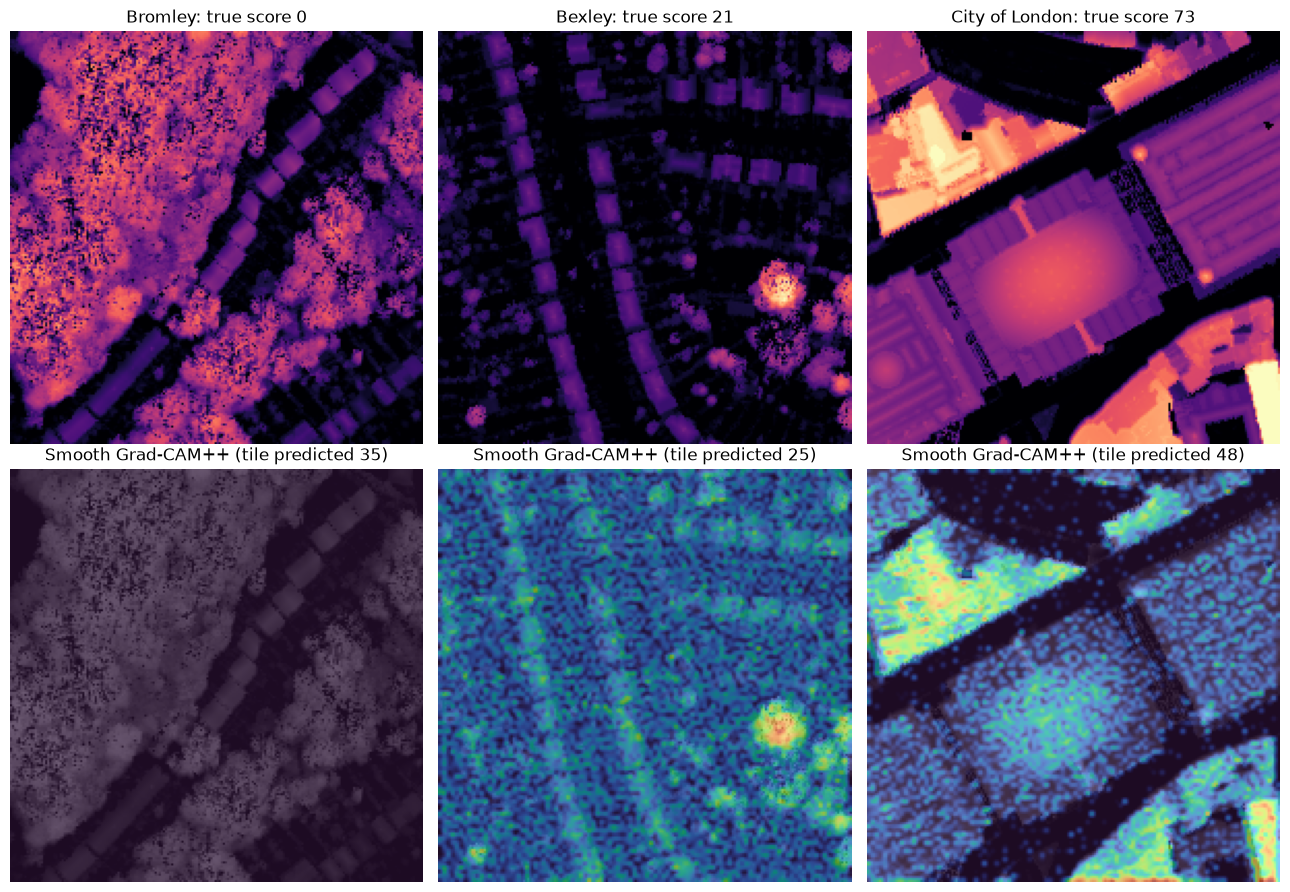

In [13]:
set_seed(0)
simple_cnn.eval()
test_scores = labels[TARGET].iloc[test_rows].sort_values()
picks = [test_scores.index[0], test_scores.index[len(test_scores) // 2], test_scores.index[-1]]

fig, ax = plt.subplots(2, 3, figsize=(13, 9))
for k, code in enumerate(picks):
    rows = np.where(tiles.LSOA11CD.values == code)[0]
    t = rows[np.argmax((images[rows] > 25).mean(axis=(1, 2)))]          # the most built-up tile of the area
    x = prepare(torch.from_numpy(images[t:t + 1]))

    cam_extractor = SmoothGradCAMpp(simple_cnn, target_layer=simple_cnn.conv_layers[4])
    output = simple_cnn(x)
    activation_map = cam_extractor(0, output)[0]                         # map for output index 0
    cam_extractor.remove_hooks()                                         # detach the extractor from the model

    heatmap = activation_map.squeeze().detach().cpu().numpy()
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
    heatmap = cv2.resize(heatmap, (images.shape[2], images.shape[1]))
    heatmap_colored = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_TURBO), cv2.COLOR_BGR2RGB)
    tile_rgb = cv2.cvtColor(images[t], cv2.COLOR_GRAY2RGB)
    overlay = cv2.addWeighted(tile_rgb, 0.4, heatmap_colored, 0.6, 0)

    ax[0, k].imshow(images[t], cmap="magma", vmin=0, vmax=255)
    ax[0, k].set_title(f"{labels.LAD19NM[code]}: true score {labels[TARGET][code]:.0f}")
    ax[1, k].imshow(overlay)
    ax[1, k].set_title(f"Smooth Grad-CAM++ (tile predicted {100 * output.item():.0f})")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

### Interpreting the heatmaps

The heatmaps show what the simple CNN reacts to: **height**. In the Bexley tile, the brightest spot is a single large tree. In the City of London tile, it is the roofs and edges of the tall office blocks. The network does not seem to tell a tree from a building, and this may explain why it predicts a score of 35 for the leafy Bromley tile, whose area has a true score of 0. For that tile the map is empty: Smooth Grad-CAM++ keeps only the regions with a positive weight, and here there are none.

As the book says, Grad-CAM tells us whether the patterns a model found make sense. Here they only partly do. Height matters for the living environment, through dense, tall blocks and through green space, but the simple CNN has not learned which kind of height is which.

## 7. Transfer learning with EfficientNet-B0 (Algorithm 2.7)

The book fine-tunes a ResNet-50 at this point, and the [original Chapter 2 lab](https://colab.research.google.com/github/Banking-Analytics-Lab/DLinBankingBook/blob/main/Labs/TextBook_Lab_Chap2_Image_Processing.ipynb) implements it exactly. Here we fine-tune **EfficientNet-B0** (Tan and Le, 2019). It has about 5 million parameters against 25 million for ResNet-50, so it trains faster on a T4, and it is the network that Part 2 uses without fine-tuning. The steps of Algorithm 2.7 map onto it one by one:

- **One input channel.** The first convolution of EfficientNet-B0 (`features[0][0]`) reads three channels. We replace it with one that reads one channel, with the sum of the pretrained red, green and blue filters as its weights. For a grey image, this gives exactly the same output as feeding the grey channel three times, at a third of the cost.
- **A regression head.** The ImageNet classifier is replaced by the head of the book: a dense layer with 256 units, ReLU, dropout of 0.5, and one output.
- **Freezing.** We freeze the whole network, then unfreeze the new first convolution, the last stage of the network (`features[7]`, with `features[8]`, the final 1 × 1 convolution), which play the role of ResNet-50's `layer4`, and the new head.

EfficientNet-B0 was trained on images normalized with the ImageNet statistics. Our batches are scaled to −1 to 1, so the model first converts them, using the average of the ImageNet channel means (0.449) and standard deviations (0.226).

In [14]:
class EfficientNetRegressor(nn.Module):
    def __init__(self, grayscale=True):
        super().__init__()

        # Pretrained EfficientNet-B0 (ImageNet weights)
        self.backbone = torchvision.models.efficientnet_b0(weights=torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1)

        # Adapt the first convolution to one input channel, keeping the pretrained filters
        if grayscale:
            rgb_conv = self.backbone.features[0][0]
            gray_conv = nn.Conv2d(1, rgb_conv.out_channels, kernel_size=rgb_conv.kernel_size,
                                  stride=rgb_conv.stride, padding=rgb_conv.padding, bias=False)
            with torch.no_grad():
                gray_conv.weight.copy_(rgb_conv.weight.sum(dim=1, keepdim=True))
            self.backbone.features[0][0] = gray_conv

        # Replace the classifier with a regression head
        self.backbone.classifier = nn.Sequential(
            nn.Linear(1280, 256),          # 1,280 features -> 256
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 1),             # one output: the score
        )

    def forward(self, x):
        x = (x * 0.5 + 0.5 - 0.449) / 0.226    # from -1..1 to the (grey) ImageNet normalization
        return self.backbone(x)


set_seed(0)
effnet = EfficientNetRegressor(grayscale=True).to(device)
with torch.no_grad():
    effnet.backbone.classifier[-1].bias.fill_(train_mean)           # start from the naive prediction

# Freeze everything, then unfreeze the parts we want to train
for param in effnet.parameters():
    param.requires_grad = False
for part in (effnet.backbone.features[0][0], effnet.backbone.features[7], effnet.backbone.features[8],
             effnet.backbone.classifier):
    for param in part.parameters():
        param.requires_grad = True

total, trainable = count_parameters(effnet)
print(f"Parameters: {total:,} in total, {trainable:,} trainable ({trainable / total:.0%})")

Parameters: 4,335,165 in total, 1,457,873 trainable (34%)


## 8. Training EfficientNet-B0 (Algorithm 2.8)

We use the same training function, with `freeze_bn=True` so that the frozen batch-normalization layers keep their pretrained statistics, and we pass the optimizer only the parameters that train. The learning rate is $10^{-4}$: in our runs it did better than $10^{-3}$ (Exercise 2). The pretrained network starts from good features, so 10 epochs are enough.

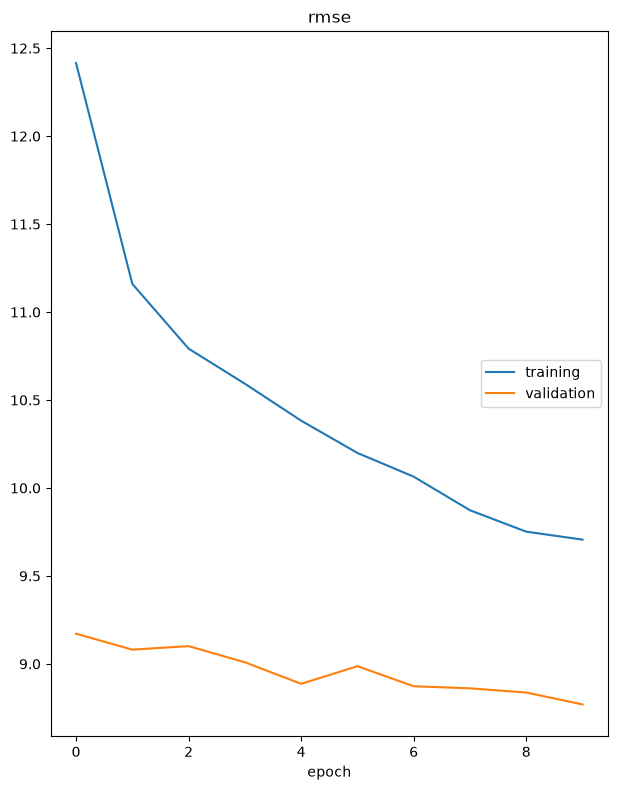

rmse
	training         	 (min:    9.706, max:   12.416, cur:    9.706)
	validation       	 (min:    8.770, max:    9.172, cur:    8.770)
Training complete. Best validation RMSE: 8.77, saved to best_efficientnet.pth
2.0 minutes


In [15]:
set_seed(0)
optimizer = torch.optim.Adam([p for p in effnet.parameters() if p.requires_grad], lr=1e-4)
t0 = time.time()
train_model(effnet, optimizer, epochs=10, checkpoint_path="best_efficientnet.pth", freeze_bn=True)
print(f"{(time.time() - t0) / 60:.1f} minutes")

## 9. Evaluation of EfficientNet-B0 (Algorithm 2.9)

In [16]:
effnet.load_state_dict(torch.load("best_efficientnet.pth", map_location=device, weights_only=True))
report("EfficientNet-B0 (fine-tuned)", *predict_areas(effnet, "test"))

pd.DataFrame(results).set_index("model").round(2)

EfficientNet-B0 (fine-tuned)       test RMSE =  8.03


,test RMSE
model,
Naive baseline: training mean,12.73
Simple CNN,10.89
EfficientNet-B0 (fine-tuned),8.03


The fine-tuned network is a pretty good model: a test RMSE of about 8.0, against 10.9 for the simple CNN and 12.7 for the baseline. In the book's case the order was the other way round, and the fine-tuned ResNet-50 did slightly worse than the simple CNN. A likely reason for the difference is the amount of data: the book fine-tuned on 248 images, and here we have more than 20,000 training tiles, enough for the pretrained features to adapt.

How good is 8.0? Section 13.1 compares it with models that use the six other domains, the structured data of this case.

---

# Part 2: beyond the book

Part 1 used the image alone, for one domain. A bank never uses an image alone: it already has structured data. Part 2 asks the question that matters in practice, for all seven domains: **does the image add to the tables?**

To answer it without leakage, every model must be fitted inside each of 15 test folds (Section 11). Fine-tuning a network for each fold and each domain would take hours. We therefore use the pretrained network **frozen**, as a feature extractor, which needs to run only once.

## 10. Image features from a frozen CNN

Here we do not train the network. We use EfficientNet-B0 as it was trained on ImageNet (1.3 million everyday photos) and use it as a **feature extractor**: we remove its last layer (the classifier over the 1,000 ImageNet classes) and keep the 1,280 numbers that its final pooling layer produces for each image. This is transfer learning in its simplest form. It is cheap, needs no labels, and runs only once for all the folds and domains.

It is the network of Section 7, before any fine-tuning. Three details:

- Our tiles have one channel; the network expects three (red, green, blue). We repeat the grey channel three times.
- The network expects 224 × 224 pixels and the ImageNet normalization (each channel minus its ImageNet mean, divided by its standard deviation). We resize the 200 × 200 tiles and normalize.
- We run the network in half precision (mixed precision, which the book uses in the case study of Section 7.5), which roughly halves the time and memory on a T4 with no loss for feature extraction.

In [17]:
# EfficientNet-B0 with ImageNet weights; replacing the classifier with Identity returns
# the 1,280-dimensional pooled features instead of the 1,000 class scores.
weights = torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1
cnn = torchvision.models.efficientnet_b0(weights=weights)
cnn.classifier = torch.nn.Identity()
cnn = cnn.eval().to(device)          # eval mode: no dropout, batch norm uses its stored statistics

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


class Tiles(Dataset):
    """Serves the tiles read in Section 2 as 3 x 224 x 224 bytes."""
    def __len__(self):
        return len(images)

    def __getitem__(self, i):
        # Grayscale -> RGB by repeating the channel, then resize to the 224 x 224 input size.
        img = Image.fromarray(images[i]).convert("RGB").resize((224, 224), Image.BILINEAR)
        return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)   # uint8, 3 x 224 x 224


@torch.no_grad()                      # no gradients: we only run the network forward
def embed(batch_size=256):
    loader = DataLoader(Tiles(), batch_size=batch_size)
    out, t0 = [], time.time()
    for x in loader:
        x = (x.to(device).float() / 255 - IMAGENET_MEAN) / IMAGENET_STD
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            out.append(cnn(x).float().cpu().numpy())
    print(f"{len(images):,} tiles embedded in {time.time() - t0:.0f} s")
    return np.concatenate(out)


features = embed()
features.shape

39,367 tiles embedded in 41 s


(39367, 1280)

### 10.1 From tiles to areas

The labels are per area, but the features are per tile, and an area can have from 1 to almost 400 tiles (the median is 5). We summarize each area by the **average** of its tile features, called mean pooling. Stevenson et al. (2022) compare mean and max pooling, and other summaries; the mean is the simplest and works well.

In [18]:
# Average the 1,280 features over the tiles of each LSOA, in the order of the label table.
area_features = (pd.DataFrame(features)
                 .groupby(tiles.LSOA11CD.values).mean()
                 .loc[labels.index].values)
print(area_features.shape)   # one row per LSOA, 1,280 columns

(4835, 1280)


## 11. Fifteen test sets of whole boroughs

Part 1 held out one group of boroughs (Section 1.3). The models of Part 2 are fast, so we use all five groups as test sets in turn, a five-fold cross-validation in which each fold's test set is a group of about 6 or 7 boroughs and the model is trained on the rest. We repeat it three times with a different assignment of boroughs to folds, which gives 15 test sets in total.

Two more rules prevent leakage:

- The 1,280 image features are too many for 4,000 areas, so we compress them with principal component analysis (PCA) to 32 components. PCA is **fitted on the training areas of each fold only**, and then applied to the test areas.
- The models only see the training areas. Any tuning (here, the Lasso penalty) happens inside the training set.

In [19]:
for r, f, tr, te in borough_folds(groups, repeats=1):
    print(f"Fold {f}: {len(tr):,} training areas, {len(te):,} test areas in", ", ".join(sorted(set(groups[te]))))

Fold 0: 3,813 training areas, 1,022 test areas in Barnet, Bexley, Bromley, City of London, Ealing, Haringey, Sutton
Fold 1: 3,737 training areas, 1,098 test areas in Croydon, Greenwich, Havering, Hillingdon, Kensington and Chelsea, Lewisham, Waltham Forest
Fold 2: 3,791 training areas, 1,044 test areas in Camden, Enfield, Kingston upon Thames, Merton, Redbridge, Southwark, Wandsworth
Fold 3: 4,020 training areas, 815 test areas in Brent, Hammersmith and Fulham, Hounslow, Richmond upon Thames, Tower Hamlets, Westminster
Fold 4: 3,979 training areas, 856 test areas in Barking and Dagenham, Hackney, Harrow, Islington, Lambeth, Newham


## 12. Models

For each of the seven domains and each fold we fit two models on three sets of inputs:

- **LightGBM**, a gradient boosting model (Ke et al., 2017), the usual first choice for tables. We use fixed, moderate settings (400 trees, learning rate 0.03, 15 leaves) and no tuning, to keep the comparison simple and fast.
- **Lasso**, a linear regression with an L1 penalty that sets weak inputs to zero. Its penalty is tuned by an inner five-fold cross-validation on the training areas.

The three sets of inputs are **D** (the six other domains), **I** (the 32 image components) and **D+I** (both, 38 inputs). We also record a **naive baseline**, the training mean, so that every number has a floor to compare with. The error measure is the root mean squared error (RMSE) on the 0 to 100 scale.

This cell runs 630 model fits and takes about four minutes.

In [20]:
def fit_predict(model, X_train, y_train, X_test):
    """Fit one model on the training areas and predict the test areas."""
    if model == "lasso":
        m = make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=5000))
    else:
        m = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15,
                              min_child_samples=20, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, verbose=-1, random_state=0)
    m.fit(X_train, y_train)
    return m.predict(X_test), m


rmse = lambda y, p: float(np.sqrt(np.mean((y - p) ** 2)))
rows = []                 # one row per (repeat, fold, domain, model, input set)
oof = {}                  # out-of-fold predictions of the first repeat, kept for Section 14

t0 = time.time()
for r, f, tr, te in borough_folds(groups):
    # PCA on the training areas of this fold only, then applied to both sides.
    pca = PCA(n_components=32, random_state=0).fit(area_features[tr])
    I_tr, I_te = pca.transform(area_features[tr]), pca.transform(area_features[te])

    for d in DOMAINS:
        y = labels[d].values
        D = labels[[o for o in DOMAINS if o != d]].values
        inputs = {"D": (D[tr], D[te]),
                  "I": (I_tr, I_te),
                  "D+I": (np.c_[D[tr], I_tr], np.c_[D[te], I_te])}
        rows.append(dict(repeat=r, fold=f, domain=d, model="mean", inputs="-",
                         rmse=rmse(y[te], y[tr].mean())))
        for model in ("lgbm", "lasso"):
            for name, (X_tr, X_te) in inputs.items():
                pred, _ = fit_predict(model, X_tr, y[tr], X_te)
                rows.append(dict(repeat=r, fold=f, domain=d, model=model, inputs=name, rmse=rmse(y[te], pred)))
                if r == 0 and model == "lgbm":
                    oof.setdefault((d, name), np.full(len(y), np.nan))[te] = pred
    print(f"repeat {r}, fold {f} done ({time.time() - t0:.0f} s)")

results_cv = pd.DataFrame(rows)

repeat 0, fold 0 done (7 s)


repeat 0, fold 1 done (14 s)


repeat 0, fold 2 done (21 s)


repeat 0, fold 3 done (27 s)


repeat 0, fold 4 done (34 s)


...

repeat 2, fold 0 done (75 s)


repeat 2, fold 1 done (82 s)


repeat 2, fold 2 done (89 s)


repeat 2, fold 3 done (96 s)


repeat 2, fold 4 done (102 s)


## 13. Results

First, the average test RMSE over the 15 folds, for every domain, model and input set, next to the naive baseline.

In [21]:
table = (results_cv[results_cv.model != "mean"]
         .pivot_table(index=["domain", "model"], columns="inputs", values="rmse")
         [["D", "I", "D+I"]])
table["mean baseline"] = results_cv[results_cv.model == "mean"].groupby("domain").rmse.mean().reindex(table.index.get_level_values(0)).values
table.round(2)

inputs                D      I    D+I  mean baseline
domain     model                                    
barriers   lasso  13.15  14.48  13.26          15.38
           lgbm   12.85  14.23  12.42          15.38
crime      lasso   9.74  10.86   9.57          12.15
           lgbm    9.87  10.67   9.34          12.15
education  lasso  11.65  14.10  10.80          16.96
           lgbm   11.39  13.93  10.20          16.96
employment lasso   4.50  12.15   4.41          14.98
           lgbm    4.67  12.21   4.54          14.98
health     lasso   9.32  12.10   9.22          14.99
           lgbm    9.19  11.94   8.40          14.99
income     lasso   4.90  13.26   4.52          17.70
           lgbm    4.85  13.27   4.52          17.70
living_env lasso  11.50   9.98   9.42          12.83
           lgbm   11.05   9.80   9.21          12.83

Three things stand out.

1. **The image alone is weak.** For income, the image features give an RMSE of about 13, against about 5 for the other six domains and about 18 for the naive mean. The frozen features hold some information (13 is better than 18), but much less than the tables already know. Living environment is the exception: there, the image alone (about 10) beats the six other domains (about 11), because housing quality and green space are partly visible from the air.
2. **The image adds to the tables.** For every domain, D+I has a lower error than D with LightGBM.
3. **Linear and nonlinear models disagree on the small effects.** Lasso, which can only add the image features linearly, gains less, and for barriers it loses a little.

Averages hide variation between folds, so we compute, for each fold, the percentage reduction in RMSE when the image is added, and report its mean with a 95% confidence interval.

In [22]:
def mean_ci(x):
    """Mean and normal-approximation 95% interval across folds."""
    x = np.asarray(x)
    se = x.std(ddof=1) / np.sqrt(len(x))
    return x.mean(), x.mean() - 1.96 * se, x.mean() + 1.96 * se


summary = []
for (d, m), g in results_cv[results_cv.model != "mean"].groupby(["domain", "model"]):
    per_fold = g.pivot_table(index=["repeat", "fold"], columns="inputs", values="rmse")
    gain = 100 * (per_fold["D"] - per_fold["D+I"]) / per_fold["D"]       # % reduction in RMSE
    mu, lo, hi = mean_ci(gain)
    summary.append(dict(domain=d, model=m, gain_pct=mu, ci_low=lo, ci_high=hi,
                        folds_improved=f"{(gain > 0).sum()} of {len(gain)}"))
summary = pd.DataFrame(summary).sort_values(["model", "gain_pct"], ascending=[True, False])
summary.round(2)

,domain,model,gain_pct,ci_low,ci_high,folds_improved
12,living_env,lasso,18.02,14.83,21.22,15 of 15
10,income,lasso,7.60,6.08,9.12,15 of 15
4,education,lasso,7.20,5.42,8.97,14 of 15
6,employment,lasso,2.19,1.70,2.69,14 of 15
2,crime,lasso,1.66,1.06,2.26,13 of 15
8,health,lasso,1.03,-0.13,2.20,11 of 15
0,barriers,lasso,-0.79,-3.02,1.45,7 of 15
13,living_env,lgbm,16.70,14.03,19.37,15 of 15
5,education,lgbm,10.50,8.78,12.22,15 of 15
9,health,lgbm,8.31,6.49,10.12,15 of 15


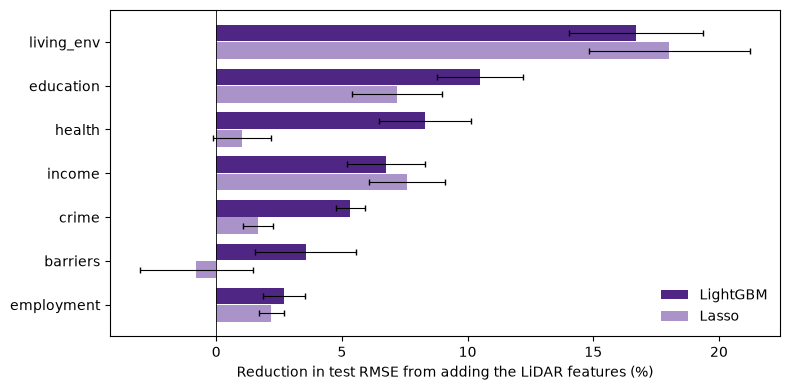

In [23]:
# The same numbers as a chart: bars are the mean reduction in RMSE, whiskers the 95% intervals.
order = summary[summary.model == "lgbm"].sort_values("gain_pct").domain.tolist()
fig, ax = plt.subplots(figsize=(8, 4))
ypos = np.arange(len(order))
for shift, (m, color, name) in zip((0.2, -0.2), [("lgbm", "#4F2683", "LightGBM"), ("lasso", "#A993C9", "Lasso")]):
    g = summary[summary.model == m].set_index("domain").loc[order]
    ax.barh(ypos + shift, g.gain_pct, height=0.38, color=color, label=name,
            xerr=[g.gain_pct - g.ci_low, g.ci_high - g.gain_pct], error_kw=dict(lw=0.8, capsize=2))
ax.axvline(0, color="black", lw=0.6)
ax.set_yticks(ypos, order)
ax.set_xlabel("Reduction in test RMSE from adding the LiDAR features (%)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

With LightGBM, adding the LiDAR features lowers the error for all seven domains, and the interval excludes zero in every case: by about 17% for living environment, 10% for education, 8% for health, 7% for income, 5% for crime, 4% for barriers and 3% for employment. With Lasso, the gains for health and barriers are not distinguishable from zero. The ranking of the domains is the one Stevenson et al. (2022) report, with somewhat smaller gains (they fine-tuned the network with self-supervised learning, SimCLR, which we skip to fit in a Colab session).

Two cautions when you read the intervals. They treat the 15 folds as independent, but folds from repeated cross-validation share training data, so the true intervals are wider. And a gain of a few percent in RMSE is a modest effect: the image is a **complement** to the structured data, not a substitute.

### 13.1 Frozen features against the networks of Part 1

The first fold of the first repeat uses the same test boroughs as Part 1, so for living environment we can put all the models side by side. LightGBM is trained on the training and validation areas of Part 1 together, and the networks only on the training areas.

In [24]:
fold0 = results_cv[(results_cv.repeat == 0) & (results_cv.fold == 0) & (results_cv.domain == TARGET)]
side = pd.concat([
    fold0.assign(model=fold0.model.map({"mean": "Naive baseline: training mean", "lgbm": "LightGBM", "lasso": "Lasso"})
                 + fold0.inputs.map(lambda s: "" if s == "-" else f" on {s}"))[["model", "rmse"]],
    pd.DataFrame(results).rename(columns={"test RMSE": "rmse"}).iloc[1:],
])
side.set_index("model").rmse.sort_values(ascending=False).round(2).to_frame("test RMSE, living environment")

,"test RMSE, living environment"
model,
Naive baseline: training mean,12.47
Simple CNN,10.89
Lasso on D,9.98
LightGBM on D,9.39
Lasso on I,8.62
LightGBM on I,8.46
EfficientNet-B0 (fine-tuned),8.03
Lasso on D+I,7.86
LightGBM on D+I,7.72


On these test boroughs, the fine-tuned network (8.03) beats every model that uses only one source of information: the six other domains (9.39 with LightGBM) and the frozen image features (8.46). Two cautions: this is a single test fold with no interval, and the networks were trained on fewer areas than LightGBM. (The naive baseline is 12.47 here, not 12.73 as in Section 5, for the same reason: LightGBM's training set includes the validation areas.)

The ranking still tells a clear story. For living environment, an image used well holds more information than the tables, the exception we saw above. And the best models of all use both sources (7.72 and 7.86), even with frozen features. Combining the fine-tuned network with the tables is the natural next step. Done without leakage, it needs a separate fine-tuning inside each fold.

## 14. What does the model use?

For living environment, the domain where the image helps most, we ask how much of each prediction comes from the image. LightGBM can split every prediction into additive contributions of its inputs (SHAP values, which Chapter 8 covers in detail) with `pred_contrib=True`. We fit the D+I model once on all areas of the first fold's training set and add up the absolute contributions of the six domains and of the 32 image components on its test set.

In [25]:
d = "living_env"
r, f, tr, te = next(borough_folds(groups, repeats=1))
pca = PCA(n_components=32, random_state=0).fit(area_features[tr])
X = np.c_[labels[[o for o in DOMAINS if o != d]].values, pca.transform(area_features)]
_, model = fit_predict("lgbm", X[tr], labels[d].values[tr], X[te])

contrib = model.predict(X[te], pred_contrib=True)[:, :-1]     # last column is the base value
share_image = np.abs(contrib[:, 6:]).sum(1) / np.abs(contrib).sum(1)
print(f"Share of the absolute contributions that comes from the image: {share_image.mean():.0%} on average")
print(f"(10th to 90th percentile across areas: {np.percentile(share_image, 10):.0%} to {np.percentile(share_image, 90):.0%})")

Share of the absolute contributions that comes from the image: 66% on average
(10th to 90th percentile across areas: 56% to 77%)


About two thirds of the living-environment prediction comes from the image (between 56 and 77 percent for most areas), even though the model also has the six other domains. Where does it change the prediction most? Below are the areas whose out-of-fold error fell the most when the image was added, with their true score and the two predictions.

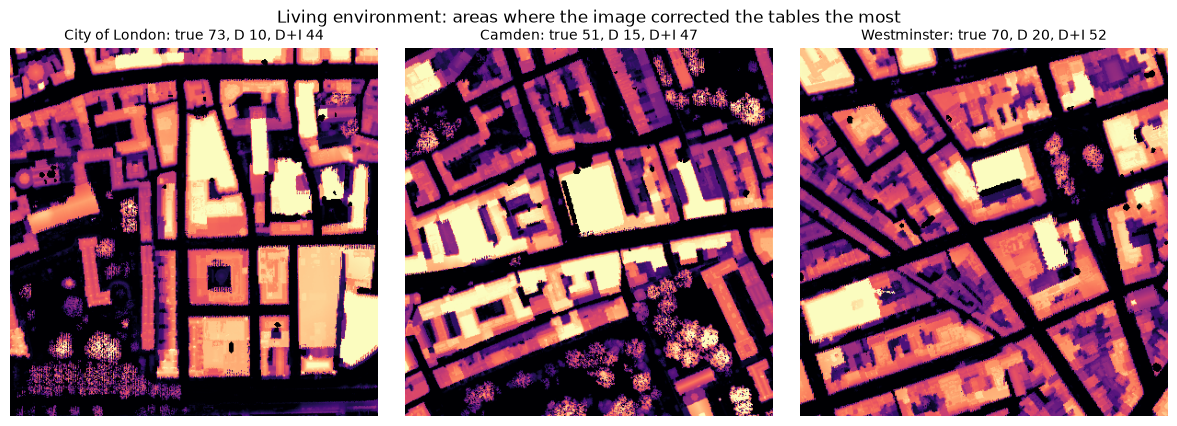

In [26]:
y = labels[d].values
p_D, p_DI = oof[(d, "D")], oof[(d, "D+I")]
better = np.abs(y - p_D) - np.abs(y - p_DI)            # positive: the image reduced the error
top = [labels.index[i] for i in np.argsort(-better) if block(labels.index[i]) is not None][:3]
idx = [labels.index.get_loc(c) for c in top]
show_areas(top, [f"{labels.LAD19NM[c]}: true {y[i]:.0f}, D {p_D[i]:.0f}, D+I {p_DI[i]:.0f}" for c, i in zip(top, idx)],
           "Living environment: areas where the image corrected the tables the most")

These are central areas (the City of London, Westminster, Camden). Their residents are not deprived in income or employment, so the tables predict a good living environment (scores of 10 to 20). But the living-environment domain also measures air quality and road traffic accidents, which are worst in exactly this kind of dense, tall, traffic-heavy center. The image shows the model what the tables cannot, and its predictions move most of the way to the true scores of 50 to 73.

Remember what the CNN is not doing in Part 2: unlike the network of Section 8, it was trained on everyday photographs, never on deprivation, and never fine-tuned. All it gives is a generic description of shapes and textures, and LightGBM learns which parts of that description matter.

## 15. What this means for a bank

Deprivation is not default. But neighborhood conditions enter credit risk in many places: in scorecards for thin-file applicants, in the valuation of collateral, in the monitoring of mortgage portfolios, and in stress tests. This lab shows a general recipe for any of them:

1. Start from the structured data you already have, and treat it as the baseline to beat.
2. Turn the images into features with a pretrained network; it is cheap and needs no labels.
3. Validate on a part of the world the model has not seen (here, whole boroughs).
4. Report the gain over the baseline with an interval, not the raw accuracy.

Two cautions specific to banking (Chapter 2, regulatory constraints, and Chapter 8). First, area features can act as **proxies for protected characteristics**: a neighborhood's built environment correlates with its ethnic and social composition. A model that uses them for decisions about individuals needs a fairness review, and in many jurisdictions a feature of this kind may only be used to help applicants (for example, in a second-look model). Second, the features come from a black box, so any use in a regulated model needs the kind of explanation we built in Sections 6 and 14.

## 16. Exercises

1. **Learning rate.** Train the simple CNN of Section 4 with learning rates of $10^{-4}$ and $10^{-3}$. Watch the validation error, and look at how much the predictions for the validation areas vary (`predict_areas(simple_cnn, "val")[1].std()`). What happens, and why might the first dense layer be the cause?
2. **Fine-tuning.** Fine-tune EfficientNet-B0 with a learning rate of $10^{-3}$, and then unfreeze one more stage (`features[6]`). Does the test error improve, or does the network start to overfit? The book asks the same question for ResNet-50.
3. **ResNet-50.** The book fine-tunes a ResNet-50 (Algorithms 2.7 to 2.9), and the [original Chapter 2 lab](https://colab.research.google.com/github/Banking-Analytics-Lab/DLinBankingBook/blob/main/Labs/TextBook_Lab_Chap2_Image_Processing.ipynb) implements it. Copy its `ResNet50Regressor` into Section 7 and compare it with EfficientNet-B0, in test error and in time per epoch.
4. **Pooling.** Replace the mean by the maximum over the tiles of each area (`.max()` instead of `.mean()` in Section 10.1). Which domains change most, and why might that be?
5. **Dimension.** Rerun Section 12 with 8 and with 64 PCA components. Does the gain grow with more image information, or does LightGBM start to overfit?
6. **A random split.** Replace `borough_folds` by a random five-fold split of the areas. How much larger do the gains look? This is the spatial leakage of Section 1.3.

## References

- Bravo, C., Maldonado, S. and Óskarsdóttir, M. (2026). *Deep Learning in Banking*. Wiley.
- Ke, G. et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems* 30.
- Omeiza, D., Speakman, S., Cintas, C. and Weldermariam, K. (2019). Smooth Grad-CAM++: An enhanced inference level visualization technique for deep convolutional neural network models. arXiv:1908.01224.
- Ministry of Housing, Communities and Local Government (2019). *The English Indices of Deprivation 2019*.
- Stevenson, M., Mues, C. and Bravo, C. (2022). Deep residential representations: Using unsupervised learning to unlock elevation data for geo-demographic prediction. *ISPRS Journal of Photogrammetry and Remote Sensing* 187, 378–392.
- Tan, M. and Le, Q. (2019). EfficientNet: Rethinking model scaling for convolutional neural networks. *Proceedings of the 36th International Conference on Machine Learning*.